# Evidence, AI and human agency

**Foundations · 20 minutes**

An observation, a prediction, an assumed scenario and a causal claim need different support. A model output or generated explanation is not automatically verified evidence. Ask who supplied the data, who is missing, who decides, and who can challenge a conclusion.

![Empathy and iteration](../assets/empathy-iteration.svg)

Original diagram, CC BY 4.0; [provenance](../visual-provenance.ipynb).

**Question:** Does an apparently complete checklist conceal a missing stakeholder? Count authored review roles. This is metadata analysis, not a measure of participation quality.


In [1]:
from IPython.display import SVG, display
from html import escape

def svg(body, title, description, width=760, height=330):
    label = escape(title, quote=True)
    display(SVG(f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" role="img" aria-label="{label}"><title>{escape(title)}</title><desc>{escape(description)}</desc><rect width="100%" height="100%" fill="#f5f5ef" rx="12"/>{body}</svg>'))

def bars(values, title, unit):
    print(title + ' | ' + unit + ':', {k:round(v,3) for k,v in values.items()})
    n = len(values)
    height = max(250, 82 + n*36)
    maximum = max(max(values.values()), 1)
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18" fill="#123c45">{escape(title)}</text>'
    for i,(key,value) in enumerate(values.items()):
        y=58+i*36
        body += f'<text x="22" y="{y+17}" font-family="sans-serif" font-size="13">{escape(str(key))}</text><rect x="205" y="{y}" width="{max(0,value)/maximum*440:.2f}" height="23" rx="3" fill="#16756b"/><text x="{213+max(0,value)/maximum*440:.2f}" y="{y+17}" font-family="sans-serif" font-size="13">{value:.2f}</text>'
    body += f'<text x="205" y="{height-15}" font-family="sans-serif" font-size="12">zero baseline · {escape(unit)}</text>'
    svg(body, title, 'Values are printed as a text alternative; consult the chart title for data status.', height=height)

def grid(values, columns, title):
    print(title + ':', [round(v,3) for v in values])
    maximum = max(max(values),1)
    size = 54
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text>'
    for i,v in enumerate(values):
        x=25+(i%columns)*size; y=52+(i//columns)*size
        light=92-50*v/maximum
        body += f'<rect x="{x}" y="{y}" width="50" height="50" fill="hsl(169,45%,{light:.1f}%)" stroke="#123c45"/><text x="{x+25}" y="{y+29}" text-anchor="middle" font-family="sans-serif" font-size="14" fill="#061c21">{v:.1f}</text>'
    svg(body,title,'Synthetic grid with values printed in each cell; no actual boundaries.',height=max(220,70+((len(values)+columns-1)//columns)*size))

def lines(series, title, xunit, yunit):
    print(title + ':', {k:[round(v,3) for v in vs] for k,vs in series.items()})
    maximum=max(max(vs) for vs in series.values()) or 1
    body=f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text><path d="M55 55V265H710" fill="none" stroke="#123c45"/>'
    for j,(name,vs) in enumerate(series.items()):
        color=['#16756b','#a34712','#41449c'][j%3]
        pts=' '.join(f'{55+i*650/max(1,len(vs)-1):.1f},{265-v*200/maximum:.1f}' for i,v in enumerate(vs))
        body+=f'<polyline points="{pts}" fill="none" stroke="{color}" stroke-width="3"/><text x="{60+j*220}" y="310" font-family="sans-serif" font-size="13" fill="{color}">{escape(name)}</text>'
    body+=f'<text x="55" y="288" font-family="sans-serif" font-size="12">{escape(xunit)} → · {escape(yunit)} ↑ · y starts at zero</text>'
    svg(body,title,'Synthetic series; printed values are the text alternative.')


Missing voices: ['community representative']
Fictional review participation | review entries: {'analyst': 2, 'service worker': 1, 'community representative': 0, 'privacy steward': 1}


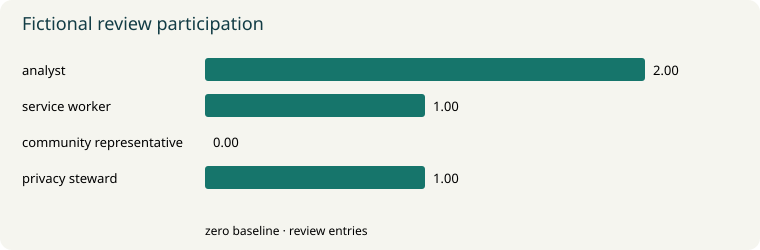

In [2]:
review = {'analyst':2, 'service worker':1, 'community representative':0, 'privacy steward':1}
print('Missing voices:', [k for k,n in review.items() if n==0])
bars(review, 'Fictional review participation', 'review entries')


## Interpret and extend

The community role has no entry. Adding a name or counting attendance is insufficient: participation requires meaningful influence, context and the possibility of disagreement. Write one open question you would ask before choosing a tool.

Use small reversible prototypes, invite critique, record changes and revisit assumptions. Protect privacy by minimizing data and precision rather than relying only on masking or encryption.

## Design thinking, human-centered design and fail-fast cycles

Use a prototype to test one assumption and learn what to change. A practical cycle is:

1. **Listen in context.** Ask people to describe their goal, constraints and existing work. Record what surprised you and whose perspective is absent.
2. **Frame a shared question.** Agree on the task, who can decide, and what evidence would change the design.
3. **Make a reversible prototype.** Start with a paper map, a small notebook or an interface mockup. Name one assumption, one success criterion and a stopping condition.
4. **Test, interpret and iterate.** Observe a realistic task, invite disagreement, document feedback and revise. Retest with people whose needs differ.

Keep an iteration record: **question | participant roles | prototype | observation | interpretation | change | next test**. Separate a participant's words from your inference. Task success and speed can inform usability; they do not measure empathy. Increasing empathy requires listening, meaningful influence and revisiting the framing, including when a preferred tool is inappropriate.

For the next workshop, sketch two legends for the same map and ask which supports the reader's task. Use invented or approved non-sensitive material. No actual user study is claimed here. IDEO.org's methods below provide practical approaches to participatory prototyping and feedback.

**Sources:** [IDEO.org Design Kit methods](https://www.designkit.org/methods.html), [WHO (2021), Ethics and governance of AI for health](https://www.who.int/publications/i/item/9789240029200), [Edward de Bono, Six Thinking Hats](https://www.debono.com/Books/six-thinking-hats). These concepts inform the original exercise and are not reproduced frameworks or endorsed deployments. [Continue to the synthesis](../synthesis/global-health.ipynb).
